# Fine-Tuning DistilBERT on IMDB: Complete Steps

**Goal**: teach a pre-trained model to classify movie reviews as positive or negative.
**Result**: accuracy went from 49.2% to 87.4%, and the model is on the Hub.

Setup → Load data → Tokenize → Load model → Train → Test → Save → Upload

Step 1: Setup
Open a new Colab notebook
`Turn on the GPU: Runtime → Change runtime type → T4 GPU`

Install the libraries:

In [3]:
!pip install transformers datasets accelerate

If Colab says “restart the runtime,” do Runtime → Restart session.

transformers gives the model and training tools.

datasets loads the data.

accelerate is the helper behind the scenes that makes training run on the GPU.

In [1]:
import torch
print(torch.cuda.is_available())

True


In [ ]:
!pip install -U datasets

# Loading the Dataset

In [1]:
from datasets import load_dataset

dataset = load_dataset("stanfordnlp/imdb")

train_data = dataset["train"].shuffle(seed=42).select(range(2000))
test_data = dataset["test"].shuffle(seed=42).select(range(500))

print(dataset)
print(train_data[0])

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})
{'text': 'There is no relation at all between Fortier and Profiler but the fact that both are police series about violent crimes. Profiler looks crispy, Fortier looks classic. Profiler plots are quite simple. Fortier\'s plot are far more complicated... Fortier looks more like Prime Suspect, if we have to spot similarities... The main character is weak and weirdo, but have "clairvoyance". People like to compare, to judge, to evaluate. How about just enjoying? Funny thing too, people writing Fortier looks American but, on the other hand, arguing they prefer American series (!!!). Maybe it\'s the language, or the spirit, but I think this series is more English than American. By the way, the actors are re

* The dataset address must be the full owner/name form (stanfordnlp/imdb). The short name imdb gave us an error.

* Train data is the practice material, and test data is the exam on unseen reviews.

* shuffle mixes the reviews, because the original data is sorted by label.

* select keeps a small slice (2000 and 500) so training takes minutes.

* Each row has text (the review) and label (0 = negative, 1 = positive).

# Tokenize the data

In [2]:
from transformers import AutoTokenizer

model_name = "distilbert/distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, padding="max_length", max_length=256)

train_tok = train_data.map(tokenize, batched=True)
test_tok = test_data.map(tokenize, batched=True)

print(train_tok[0].keys())

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

dict_keys(['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'])


* Models understand only numbers, so the tokenizer converts each review into input_ids.

* truncation=True cuts long reviews, and padding="max_length" pads short ones, so every review is exactly 256 tokens.

* The new column attention_mask tells the model which tokens are real (1) and which are padding (0).

* The tokenizer and model must match, so both use the same model_name.

# Load the Model

In [3]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


* This downloads DistilBERT’s pre-trained weights and adds a small new classification layer with 2 outputs.

* The warning about “weights not initialized” is normal. It means the new layer is untrained, and that is what fine-tuning will teach.

* Before training, the model’s guesses were about 50/50 (our “before” picture).

In [4]:
import torch

text = "This movie was fantastic!"
inputs = tokenizer(text, return_tensors="pt")
with torch.no_grad():
    logits = model(**inputs).logits
print(logits.softmax(dim=-1))

tensor([[0.4552, 0.5448]])


# Train (fine-tune) the model and evaluate the accuracy before and after

In [5]:
import numpy as np
from transformers import TrainingArguments, Trainer

def compute_accuracy(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {"accuracy": (predictions == labels).mean()}

args = TrainingArguments(
    output_dir="distilbert-imdb",
    num_train_epochs=2,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="no",
    fp16=True,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_tok,
    eval_dataset=test_tok,
    compute_metrics=compute_accuracy,
)

print("BEFORE training:", trainer.evaluate())
trainer.train()
print("AFTER training:", trainer.evaluate())

Training Loss,Validation Loss,Epoch,Accuracy
No log,0.697106,0,0.492000


BEFORE training: {'eval_loss': 0.6971064209938049, 'eval_accuracy': 0.492}


Epoch,Training Loss,Validation Loss,Accuracy
1,No log,0.330329,0.846000
2,No log,0.308428,0.874000


Training Loss,Validation Loss,Epoch,Accuracy
No log,0.308428,2,0.874000


AFTER training: {'eval_loss': 0.30842816829681396, 'eval_accuracy': 0.874}


Here, after fine-tuning the model it improved the accuracy from 49.2% to 87.4%.
this shows that the fine-tuning worked.

* compute_accuracy is the scoring function. It checks how often the model’s guess equals the true label.

* TrainingArguments is the settings sheet:
num_train_epochs=2: go through the data 2 times
batch_size=16: study 16 reviews at a time
learning_rate=2e-5: small, gentle learning steps, so we don’t break what the model already knows

* fp16=True: smaller numbers, so training is faster on the GPU

* Trainer is the coach. It runs the whole loop: guess, measure the error, adjust, repeat.
Calling evaluate() before and after shows the improvement.

Our results:
Accuracy
```
Before	49.2%
After epoch 1	84.6%
After epoch 2	87.4%

```



# Testing the fine-tuned Model

In [6]:
import torch

model.eval()

texts = [
    "This movie was fantastic!",
    "What a waste of time, I hated every minute.",
    "The acting was great but the story was boring.",
]

for text in texts:
    inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=256).to(model.device)
    with torch.no_grad():
        probs = model(**inputs).logits.softmax(dim=-1)[0]
    label = "POSITIVE" if probs[1] > probs[0] else "NEGATIVE"
    print(f"{text}\n  -> {label}  (neg={probs[0]:.3f}, pos={probs[1]:.3f})\n")

This movie was fantastic!
  -> POSITIVE  (neg=0.054, pos=0.946)

What a waste of time, I hated every minute.
  -> NEGATIVE  (neg=0.931, pos=0.069)

The acting was great but the story was boring.
  -> NEGATIVE  (neg=0.918, pos=0.082)



* model.eval() switches to “just predict” mode.

* softmax turns the two raw scores into probabilities, and the bigger one decides the label.

# Save and reload locally

In [7]:
model.config.id2label = {0: "NEGATIVE", 1: "POSITIVE"}
model.config.label2id = {"NEGATIVE": 0, "POSITIVE": 1}

model.save_pretrained("my-distilbert-imdb")
tokenizer.save_pretrained("my-distilbert-imdb")

from transformers import pipeline

clf = pipeline("text-classification", model="my-distilbert-imdb", device=0)
print(clf("I really enjoyed this film!"))
print(clf("This was a boring, painful movie."))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[{'label': 'POSITIVE', 'score': 0.9536116719245911}]
[{'label': 'NEGATIVE', 'score': 0.9105405807495117}]


* The first two lines give the labels real names (NEGATIVE/POSITIVE) instead of LABEL_0/LABEL_1.

* save_pretrained saves the weights, config, and tokenizer into a folder. The model and tokenizer always travel together.

* Colab’s files are deleted when the session ends, so this folder is only temporary.

# Uploading the Model to the hub

a. Create a token: on (https://huggingface.co]) go to Settings → Access Tokens → Create new token, choose Write, and copy it.

b. Store it safely: in Colab, click the 🔑 Secrets icon, add a secret named HF_TOKEN with your token as the value, and turn on Notebook access.

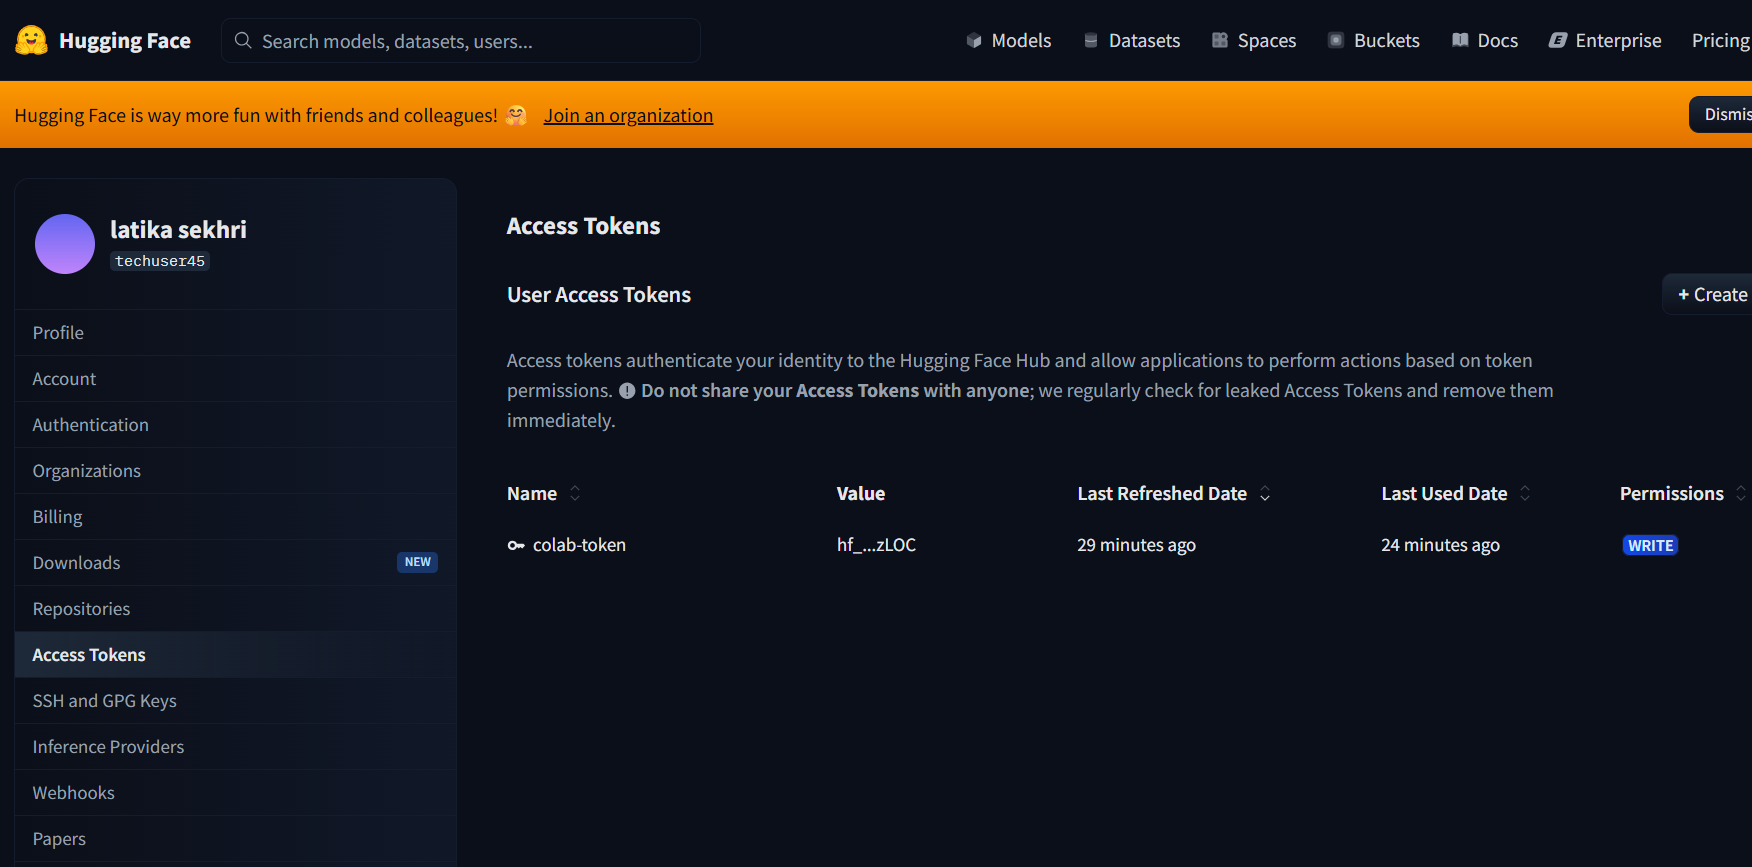

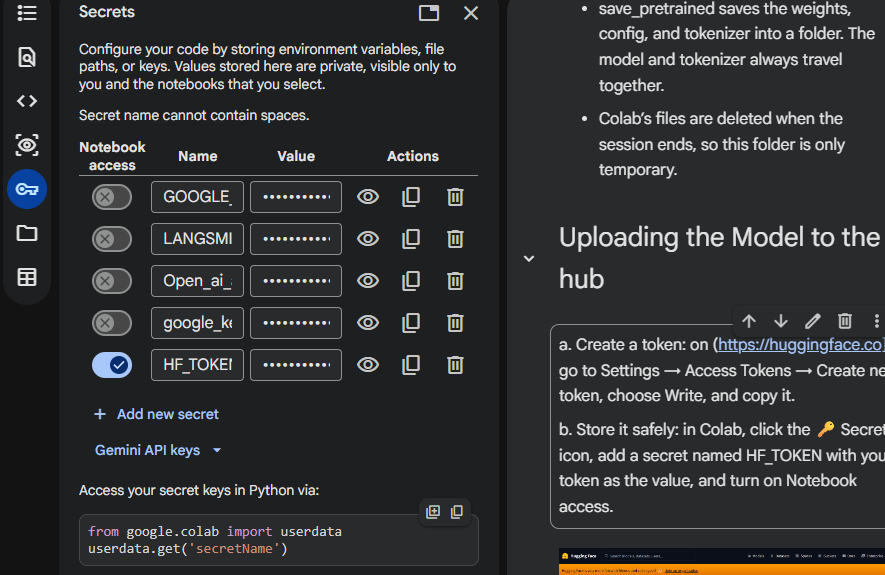

In [14]:
from google.colab import userdata
from huggingface_hub import login

token = userdata.get("HF_TOKEN")
login(token=token)
# except Exception as e:
#     print(f"Could not login with stored secret: {e}")
#     print("Please login interactively below:")
#     login()

# Push the Model

This creates a repo on your account and uploads the files. It is public by default (add private=True to keep it private).

Never paste your token in a code cell or in chat. Keep it in Secrets.

In [15]:
repo_name = "my-distilbert-imdb"

model.push_to_hub(repo_name)
tokenizer.push_to_hub(repo_name)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...qx0psk6/model.safetensors:   0%|          |  575kB /  268MB            

Validating                    :           |   0%            

README.md:   0%|          | 0.00/5.17k [00:00<?, ?B/s]

CommitInfo(commit_url='https://huggingface.co/techuser45/my-distilbert-imdb/commit/7721b75b99ae18cc3b41dc3587fbde23e9cce9a4', commit_message='Upload tokenizer', commit_description='', oid='7721b75b99ae18cc3b41dc3587fbde23e9cce9a4', pr_url=None, repo_url=RepoUrl('https://huggingface.co/techuser45/my-distilbert-imdb', endpoint='https://huggingface.co', repo_type='model', repo_id='techuser45/my-distilbert-imdb'), pr_revision=None, pr_num=None)

# Proving that it works after loading from hub

In [17]:
from huggingface_hub import whoami
from transformers import pipeline

username = whoami()["name"]
hub_id = f"{username}/my-distilbert-imdb"
print("Loading:", hub_id)

hub_clf = pipeline("text-classification", model=hub_id, device=0)
print(hub_clf("An absolutely wonderful story with great acting."))
print(hub_clf("I want my two hours back."))

Loading: techuser45/my-distilbert-imdb


config.json:   0%|          | 0.00/784 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/351 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

[{'label': 'POSITIVE', 'score': 0.9493732452392578}]
[{'label': 'POSITIVE', 'score': 0.6216652393341064}]


This proves your model is truly published, because anyone can now load it with owner/name.

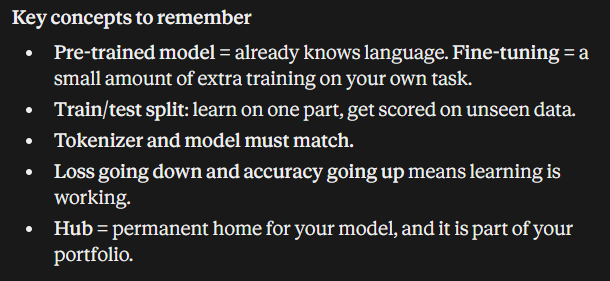